In [1]:
# load environment
from dotenv import load_dotenv
load_dotenv() # this will make sure env variable is readily available when tried prompt to AI model


# cehck env vars
import os
# gogoleApikey = os.getenv('GOOGLE_API_KEY')
# print(gogoleApikey)


# loading loan info into pages
from langchain_community.document_loaders import PyPDFLoader, TextLoader, WebBaseLoader
loader = TextLoader("banking-rules-info.txt")
txt_pages = loader.load()
print(f'No of pages: {len(txt_pages)}')


# Separating info pages into chunks
from langchain_text_splitters import RecursiveCharacterTextSplitter
splitter = RecursiveCharacterTextSplitter(
    chunk_size=300,
    chunk_overlap=50,
           separators=["\n\n", "\n", ",", " "]
)
chunk_documents = splitter.split_documents(txt_pages);
print(f'No of chunks: {len(chunk_documents)}')


# creating vector database from document chunks
from langchain_ollama import OllamaEmbeddings
from langchain_community.vectorstores import FAISS
embedding_model = OllamaEmbeddings(model="nomic-embed-text")
print('Embedding model is ready')

loan_info_vector_store = FAISS.from_documents(chunk_documents, embedding_model)
loan_info_vector_store. save_local("loan-info-vector-store")
print('Loan Info Vector store created')


# Build retrieval to be used later in Langgraph
# retriever = loan_info_vector_store.as_retriever()

# Define Loan application state
from typing import List, TypedDict, Annotated
#from langchain_core.messages import AnyMessage
#from langgraph.graph.message import add_messages
from langchain_core.documents import Document

class LoanAppState(TypedDict):
    salary: int          # input
    credit_score: int    # input
    age: int             # input
    #applyingFor: str     # input
    rulesInfoDocs: List[Document]
    llmResponse: str     # internal
    isEligible: bool     # output
print('Loan applciation state is ready .. ')

C:\Users\User\AppData\Local\Temp\ipykernel_13228\1156945415.py:13: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader, TextLoader, WebBaseLoader
USER_AGENT environment variable not set, consider setting it to identify your requests.


No of pages: 1
No of chunks: 12
Embedding model is ready
Loan Info Vector store created
Loan applciation state is ready .. 


model is ready...
Loan StateGraph is ready ... 
------------------  Application ready to be used --------------------


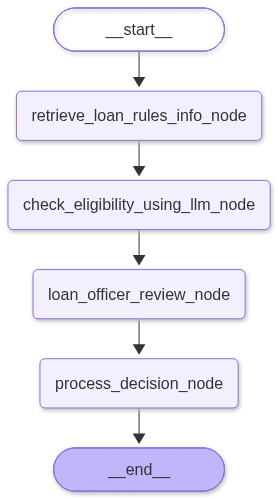

In [ ]:
# Nodes are created from here

#import ollama
from langchain_core.prompts import PromptTemplate
from langchain_ollama import ChatOllama
model = ChatOllama(model="llama3.2:latest")
print("model is ready...")

def retrieve_loan_rules_info(state: LoanAppState):
    rulesInfoDocs = loan_info_vector_store.as_retriever().invoke("Find rules for loan application eligibility")
    #print(f'Retrieved rules info: {rulesInfoDocs}')
    return { 'rulesInfoDocs': rulesInfoDocs }

def check_eligibility_using_llm(state: LoanAppState):
    USER_PROMPT_TEMPLATE = """
        You're loan approver officer. Please consider following loan application rules to decide
        whether loan applciation should be approved or not.
        Please respond in following JSON format 
        Please do not try to answer if you do not find relevant info from it.
        {sys_context}
        Input for Application loan details are:
        Salary: {input_salary}
        Credit Score: {input_credit_score}
        Age: {input_age}
    """
    prompt_template = PromptTemplate(
        template=USER_PROMPT_TEMPLATE,
        input_variables=["sys_context", "input_salary", "input_credit_score", "input_age"]
    )
    rag_context = "\n\n".join(
        document.page_content for document in state["rulesInfoDocs"]
    )
    messages = prompt_template.invoke({
        "sys_context": rag_context,
        "input_salary": state["salary"],
        "input_credit_score": state["credit_score"],
        "input_age": state["age"]
    })
    llmResponse = model.invoke(messages)
    print("")
    print("")
    print("------------------  Response recveived from LLM (start) --------------------")
    print(llmResponse)
    print("------------------  Response recveived from LLM (end) --------------------")
    print(type(llmResponse.content))
    print("")
    print("")
    
    # state["llmResponse"] = llmResponse.content
    return { 
        "llmResponse": llmResponse.content, 
        "isEligible": False 
    }

from langgraph.types import Command, interrupt

def loan_officer_review(state: LoanAppState):
    """LLM response will be reviewed by human and approve/reject will be given back"""
        
    question_to_human = f"""
        Below is the llm response for eligibility check for a loan application from llm
        {state['llmResponse']}
        Can you please check approval?
    """
    #approved = interrupt("Approve this application? (yes/no)")
    
    approved = interrupt(
        {
            "message": question_to_human,
            "options": ["accept", "reject"],
        }
    )
    
    return { "isEligible": approved == "accept"}
    
def process_decision(state: LoanAppState):
    if state["isEligible"] == True:
        print("Success")
    else:
        print("Rejected")

    return state

# Build graph
from langgraph.graph import StateGraph, START, END

graph_builder = StateGraph(LoanAppState)

# Node registration
#graph_builder.add_node("loan_application_input_node", loan_application_input)
graph_builder.add_node("retrieve_loan_rules_info_node", retrieve_loan_rules_info)
graph_builder.add_node("check_eligibility_using_llm_node", check_eligibility_using_llm)
graph_builder.add_node("loan_officer_review_node", loan_officer_review)
graph_builder.add_node("process_decision_node", process_decision)

# Add edges
graph_builder.add_edge(START, "retrieve_loan_rules_info_node")
graph_builder.add_edge("retrieve_loan_rules_info_node", "check_eligibility_using_llm_node")
graph_builder.add_edge("check_eligibility_using_llm_node", "loan_officer_review_node")
graph_builder.add_edge("loan_officer_review_node", "process_decision_node")
graph_builder.add_edge("process_decision_node", END)

graph = graph_builder.compile()
print('Loan StateGraph is ready ... ')

print('------------------  Application ready to be used --------------------')
graph